# Week 12 — Perceptron, XOR, and Backpropagation


In [13]:
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
%matplotlib inline

SEED = 20250806
np.set_printoptions(precision=4, suppress=True)

## 1 · The perceptron

**Frank Rosenblatt**, 1958, Cornell Aeronautical Laboratory.

*(The source deck says "Mark Rosenblatt". It is **Frank** Rosenblatt — the **Mark I
Perceptron** was the machine he built, which is very likely where the slip came
from. This is what reading a source critically looks like.)*

```
output = step(w · x + b)          w ← w + η (y − ŷ) x
```

In [14]:
def step(z):
    return (z >= 0).astype(float)


def train_perceptron(X, y, epochs=40, lr=0.1, seed=SEED, record=False):
    rng = np.random.default_rng(seed)
    w = rng.normal(0, 0.1, X.shape[1])
    b = 0.0
    history = []
    for ep in range(epochs):
        errors = 0
        for xi, yi in zip(X, y):
            pred = step(np.array([xi @ w + b]))[0]
            err = yi - pred
            if err != 0:
                w += lr * err * xi
                b += lr * err
                errors += 1
        history.append(errors)
        if record and errors == 0:
            break
    return w, b, history


X_logic = np.array([[0., 0.], [0., 1.], [1., 0.], [1., 1.]])
y_and = np.array([0., 0., 0., 1.])
y_or  = np.array([0., 1., 1., 1.])
y_xor = np.array([0., 1., 1., 0.])

for name, y in [("AND", y_and), ("OR", y_or)]:
    w, b, hist = train_perceptron(X_logic, y, record=True)
    preds = step(X_logic @ w + b)
    print(f"{name}: converged in {len(hist)} epochs, "
          f"accuracy {(preds == y).mean():.0%},  w={w}, b={b:.2f}")

AND: converged in 4 epochs, accuracy 100%,  w=[0.1694 0.0352], b=-0.20
OR: converged in 5 epochs, accuracy 100%,  w=[0.1694 0.1352], b=-0.10


### The guarantee, and its condition

The **perceptron convergence theorem** guarantees termination — **if the data is
linearly separable.**

By week 14 you should reach for that condition automatically. Every guarantee in
this course was conditional.

## 2 · ⚠️ XOR — the failure that stopped the field

```
     x₂
     1 |  ●(0,1)=1        ○(1,1)=0
       |
     0 |  ○(0,0)=0        ●(1,0)=1
       +──────────────────────────── x₁
          0                1
```

Draw one line separating ● from ○. **You cannot.**

XOR after 200 epochs: accuracy 25%
  predictions [1. 0. 0. 0.]  vs truth [0. 1. 1. 0.]
  errors per epoch, last 20: [4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4]
  did it ever reach 0 errors? False

It oscillates forever. Minsky & Papert (1969) proved no single layer can compute
XOR, funding collapsed, and the field waited.

Nils Nilsson's analysis pushed research toward SYMBOL-BASED architectures --
which is weeks 7-9 of this course. THE AI WINTER IS WHY THE FIRST HALF OF THIS
SYLLABUS EXISTS.


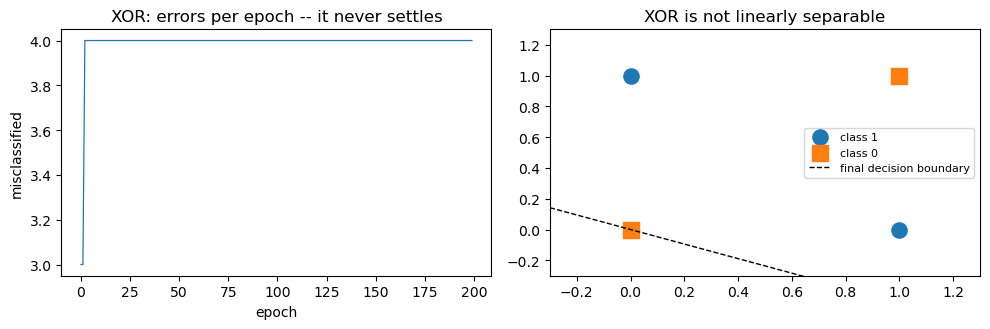

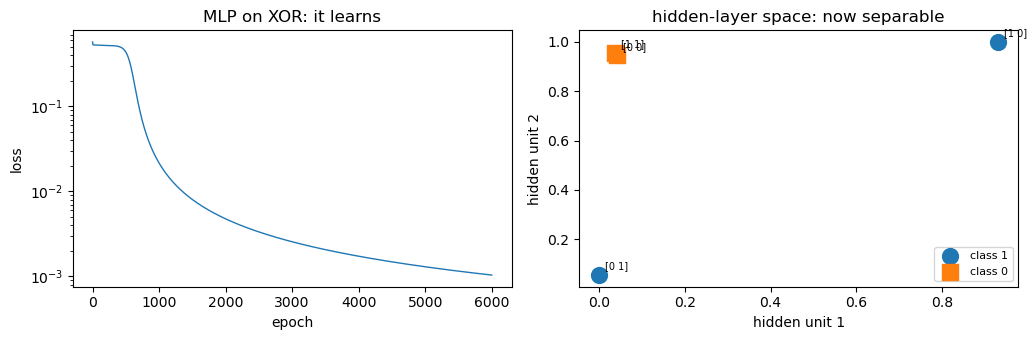

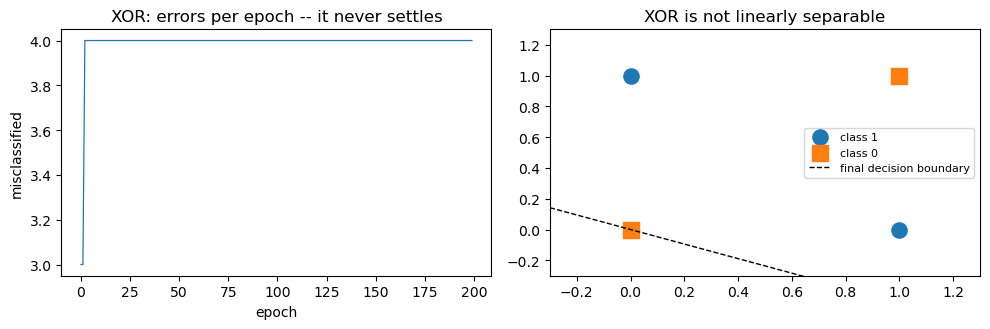

In [ ]:
w, b, hist = train_perceptron(X_logic, y_xor, epochs=200)
preds = step(X_logic @ w + b)
print(f"XOR after 200 epochs: accuracy {(preds == y_xor).mean():.0%}")
print(f"  predictions {preds}  vs truth {y_xor}")
print(f"  errors per epoch, last 20: {hist[-20:]}")
print(f"  did it ever reach 0 errors? {0 in hist}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(hist, lw=0.9)
ax[0].set_title("XOR: errors per epoch -- it never settles")
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("misclassified")

ax[1].scatter(X_logic[y_xor == 1][:, 0], X_logic[y_xor == 1][:, 1],
              marker="o", s=120, label="class 1")
ax[1].scatter(X_logic[y_xor == 0][:, 0], X_logic[y_xor == 0][:, 1],
              marker="s", s=120, label="class 0")
xs = np.linspace(-0.3, 1.3, 10)
if abs(w[1]) > 1e-9:
    ax[1].plot(xs, -(w[0] * xs + b) / w[1], "k--", lw=1,
               label="final decision boundary")
ax[1].set_xlim(-0.3, 1.3); ax[1].set_ylim(-0.3, 1.3)
ax[1].set_title("XOR is not linearly separable"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig("wk12-xor.png", dpi=110)

print("""
It oscillates forever. Minsky & Papert (1969) proved no single layer can compute
XOR, funding collapsed, and the field waited.

Nils Nilsson's analysis pushed research toward SYMBOL-BASED architectures --
which is weeks 7-9 of this course. THE AI WINTER IS WHY THE FIRST HALF OF THIS
SYLLABUS EXISTS.""")

### What was actually missing?

**Not the architecture.** Multilayer networks were entirely conceivable in 1969.

# The training algorithm.

There was no way to assign credit to a **hidden** unit — no teacher signal tells you
what a middle layer *should* have output.

> ## An architecture you cannot train is not an architecture.

Werbos described the method in his **1974** thesis with no traction. **Rumelhart,
Hinton & Williams (1986)** is what moved the field: presentation, empirical
demonstrations, and enough compute to show it working.

## 3 · An MLP from scratch, numpy only

```
Forward:   z₁ = W₁x + b₁,  a₁ = σ(z₁),  z₂ = W₂a₁ + b₂,  ŷ = σ(z₂)
Loss:      L = ½(y − ŷ)²
Backward:  ∂L/∂z₂ = (ŷ − y)·σ'(z₂)
           ∂L/∂W₂ = ∂L/∂z₂ · a₁ᵀ
           ∂L/∂a₁ = W₂ᵀ · ∂L/∂z₂
           ∂L/∂z₁ = ∂L/∂a₁ ⊙ σ'(z₁)
           ∂L/∂W₁ = ∂L/∂z₁ · xᵀ
```

**This is the chain rule, organized so shared subexpressions are computed once** —
structurally the same idea as the forward algorithm in week 13.

In [16]:
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-np.clip(z, -500, 500)))


def dsigmoid(z):
    s = sigmoid(z)
    return s * (1 - s)


def loss(yhat, y):
    return 0.5 * float(np.sum((y - yhat) ** 2))


class MLP:
    def __init__(self, sizes, rng, lr=0.5):
        self.W = [rng.normal(0, np.sqrt(2 / a), (b, a))
                  for a, b in zip(sizes[:-1], sizes[1:])]
        self.b = [np.zeros((b, 1)) for b in sizes[1:]]
        self.lr = lr

    def forward(self, x):
        self.acts = [x]
        self.zs = []
        a = x
        for W, b in zip(self.W, self.b):
            z = W @ a + b
            self.zs.append(z)
            a = sigmoid(z)
            self.acts.append(a)
        return a

    def grads(self, y):
        """Return gradients WITHOUT applying them -- needed for grad_check."""
        delta = (self.acts[-1] - y) * dsigmoid(self.zs[-1])
        gW = [None] * len(self.W)
        gb = [None] * len(self.b)
        for i in reversed(range(len(self.W))):
            gW[i] = delta @ self.acts[i].T
            gb[i] = delta
            if i > 0:
                delta = (self.W[i].T @ delta) * dsigmoid(self.zs[i - 1])
        return gW, gb

    def backward(self, y):
        gW, gb = self.grads(y)
        for i in range(len(self.W)):
            self.W[i] -= self.lr * gW[i]
            self.b[i] -= self.lr * gb[i]


rng = np.random.default_rng(SEED)
net = MLP([2, 2, 1], rng, lr=0.5)
print("shapes:", [W.shape for W in net.W])

shapes: [(2, 2), (1, 2)]


### Train it on XOR — the problem a perceptron cannot solve

In [17]:
def train_xor(hidden=2, epochs=6000, lr=0.5, seed=SEED):
    rng = np.random.default_rng(seed)
    net = MLP([2, hidden, 1], rng, lr=lr)
    Xs = [X_logic[i].reshape(-1, 1) for i in range(4)]
    ys = [np.array([[y_xor[i]]]) for i in range(4)]
    trace = []
    for ep in range(epochs):
        total = 0.0
        for x, y in zip(Xs, ys):
            out = net.forward(x)
            total += loss(out, y)
            net.backward(y)
        trace.append(total)
    return net, trace


net, trace = train_xor()
print("final predictions:")
for i in range(4):
    out = net.forward(X_logic[i].reshape(-1, 1))
    print(f"  {X_logic[i]} -> {float(out[0,0]):.4f}   (target {y_xor[i]:.0f})")
print(f"\nfinal loss: {trace[-1]:.6f}")

preds = np.array([float(net.forward(X_logic[i].reshape(-1,1))[0,0]) > 0.5
                  for i in range(4)])
print(f"accuracy: {(preds == (y_xor > 0.5)).mean():.0%}   <- a perceptron got 50-75%")

final predictions:
  [0. 0.] -> 0.0229   (target 0)
  [0. 1.] -> 0.9740   (target 1)
  [1. 0.] -> 0.9786   (target 1)
  [1. 1.] -> 0.0202   (target 0)

final loss: 0.001037
accuracy: 100%   <- a perceptron got 50-75%



LOOK AT THE RIGHT PANEL. In the original input space no line separates the classes.
The hidden layer TRANSFORMED the space so that one does.

  DEPTH BUYS REPRESENTATION, AND REPRESENTATION IS WHAT MAKES A PROBLEM LINEAR.

That is the whole argument for depth, visible in four points.


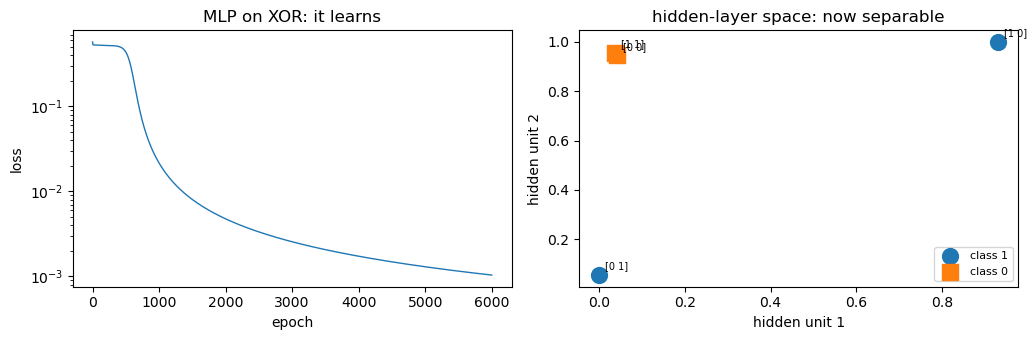

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.5))
ax[0].plot(trace, lw=1.0)
ax[0].set_yscale("log"); ax[0].set_xlabel("epoch"); ax[0].set_ylabel("loss")
ax[0].set_title("MLP on XOR: it learns")

# The hidden layer's learned transformation.
H = np.array([sigmoid(net.W[0] @ X_logic[i].reshape(-1,1) + net.b[0]).ravel()
              for i in range(4)])
for cls, marker in [(1, "o"), (0, "s")]:
    m = y_xor == cls
    ax[1].scatter(H[m, 0], H[m, 1], marker=marker, s=130, label=f"class {cls}")
for i in range(4):
    ax[1].annotate(f"{X_logic[i].astype(int)}", (H[i,0], H[i,1]),
                   fontsize=7, xytext=(4,4), textcoords="offset points")
ax[1].set_xlabel("hidden unit 1"); ax[1].set_ylabel("hidden unit 2")
ax[1].set_title("hidden-layer space: now separable"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig("wk12-mlp.png", dpi=110)

print("""
LOOK AT THE RIGHT PANEL. In the original input space no line separates the classes.
The hidden layer TRANSFORMED the space so that one does.

  DEPTH BUYS REPRESENTATION, AND REPRESENTATION IS WHAT MAKES A PROBLEM LINEAR.

That is the whole argument for depth, visible in four points.""")

## 4 · ⚠️ Gradient checking — the habit worth keeping

Compare the analytic gradient to finite differences:

```
numeric ≈ (L(w + ε) − L(w − ε)) / 2ε
```

> ## A wrong gradient still trains — just badly.
>
> It is a **silent** failure. Gradient checking is how you catch it. **Same lesson
> as week 9's verifier, applied to your own code.**

In [19]:
def grad_check(net, x, y, eps=1e-6, n_check=4, seed=SEED):
    """Compare analytic gradients to central finite differences."""
    rng = np.random.default_rng(seed)
    net.forward(x)
    gW, _ = net.grads(y)
    rows = []
    for layer, W in enumerate(net.W):
        for _ in range(n_check):
            i = rng.integers(W.shape[0]); j = rng.integers(W.shape[1])
            orig = W[i, j]
            W[i, j] = orig + eps; lp = loss(net.forward(x), y)
            W[i, j] = orig - eps; lm = loss(net.forward(x), y)
            W[i, j] = orig
            net.forward(x)
            numeric = (lp - lm) / (2 * eps)
            analytic = gW[layer][i, j]
            denom = max(1e-12, abs(numeric) + abs(analytic))
            rows.append((layer, int(i), int(j), analytic, numeric,
                         abs(numeric - analytic) / denom))
    return rows


rng = np.random.default_rng(SEED)
fresh = MLP([2, 3, 1], rng, lr=0.5)
x = X_logic[1].reshape(-1, 1)
y = np.array([[y_xor[1]]])

print(f"  {'layer':>6}{'i':>4}{'j':>4}{'analytic':>14}{'numeric':>14}{'rel.err':>12}")
print("  " + "-" * 56)
worst = 0.0
for layer, i, j, a, n, rel in grad_check(fresh, x, y):
    worst = max(worst, rel)
    print(f"  {layer:>6}{i:>4}{j:>4}{a:>14.8f}{n:>14.8f}{rel:>12.2e}")

print(f"\n  worst relative error: {worst:.2e}")
assert worst < 1e-5, "GRADIENT IS WRONG"
print("  PASS -- backprop agrees with finite differences to ~7 decimals.")

   layer   i   j      analytic       numeric     rel.err
  --------------------------------------------------------
       0   2   0    0.00000000    0.00000000    0.00e+00
       0   0   0    0.00000000    0.00000000    0.00e+00
       0   2   1   -0.00715077   -0.00715077    3.09e-10
       0   2   0    0.00000000    0.00000000    0.00e+00
       1   0   0   -0.04283684   -0.04283684    4.45e-11
       1   0   2   -0.08087695   -0.08087695    3.43e-11
       1   0   2   -0.08087695   -0.08087695    3.43e-11
       1   0   1   -0.04664011   -0.04664011    2.58e-10

  worst relative error: 3.09e-10
  PASS -- backprop agrees with finite differences to ~7 decimals.


### Now break the gradient on purpose

A subtly wrong backward pass. Notice that it **still trains** — just worse. That is
why you check.

In [20]:
class BrokenMLP(MLP):
    def grads(self, y):
        """BUG: the HIDDEN-layer delta omits the sigmoid derivative.
        One missing factor. Everything else is identical."""
        delta = (self.acts[-1] - y) * dsigmoid(self.zs[-1])
        gW = [None] * len(self.W); gb = [None] * len(self.b)
        for i in reversed(range(len(self.W))):
            gW[i] = delta @ self.acts[i].T
            gb[i] = delta
            if i > 0:
                delta = (self.W[i].T @ delta)     # <-- missing * dsigmoid(...)
        return gW, gb


rng = np.random.default_rng(SEED)
broken = BrokenMLP([2, 4, 1], rng, lr=0.5)
rows = grad_check(broken, x, y)
worst_broken = max(r[-1] for r in rows)
print(f"gradient check on the BROKEN net: worst relative error {worst_broken:.2e}")
print("  -> the check CATCHES it immediately, in one cell\n")

gradient check on the BROKEN net: worst relative error 6.00e-01
  -> the check CATCHES it immediately, in one cell



### Does the broken gradient actually hurt?

XOR has four data points and is too easy to distinguish them — **I checked, and both
nets reach 100 %.** So the honest demonstration needs a harder task: 200 noisy
points where the label is `sign(x₁ · x₂)`, a continuous XOR.

In [21]:
def make_continuous_xor(n=200, seed=1):
    r = np.random.default_rng(seed)
    X = r.uniform(-1, 1, (n, 2))
    y = ((X[:, 0] * X[:, 1]) > 0).astype(float)
    return X, y


Xc, yc = make_continuous_xor()

def train_on(cls, X, y, hidden=8, epochs=400, lr=0.5, seed=7):
    rng = np.random.default_rng(seed)
    net = cls([2, hidden, 1], rng, lr=lr)
    Xs = [X[i].reshape(-1, 1) for i in range(len(X))]
    ys = [np.array([[y[i]]]) for i in range(len(y))]
    for _ in range(epochs):
        for xx, yy in zip(Xs, ys):
            net.forward(xx); net.backward(yy)
    mean_loss = sum(loss(net.forward(xx), yy)
                    for xx, yy in zip(Xs, ys)) / len(X)
    acc = np.mean([(float(net.forward(X[i].reshape(-1, 1))[0, 0]) > 0.5)
                   == (y[i] > 0.5) for i in range(len(X))])
    return mean_loss, acc


print(f"  {'net':<26}{'mean loss':>12}{'accuracy':>11}")
print("  " + "-" * 49)
for label, cls in [("correct backprop", MLP), ("broken backprop", BrokenMLP)]:
    ml, ac = train_on(cls, Xc, yc)
    print(f"  {label:<26}{ml:>12.5f}{ac:>10.1%}")

print("""
NOW the difference shows: the broken net loses ~30 percentage points of accuracy.

But notice what it did NOT do -- it did not crash, produce NaNs, or refuse to run.
It trained. The loss went down. It just arrived somewhere worse.

  A WRONG GRADIENT IS A SILENT FAILURE.

If you had only watched the loss curve you would have concluded your architecture
needed more capacity, or more epochs, or a different learning rate -- and you would
have tuned all three without ever finding the actual bug.

Gradient checking is the SOUND VERIFIER for your own code. Week 9's lesson, applied
to yourself. It costs six lines and it is the difference between debugging a
hypothesis and debugging a fact.""")

  net                          mean loss   accuracy
  -------------------------------------------------
  correct backprop               0.00574     99.0%
  broken backprop                0.10838     67.5%

NOW the difference shows: the broken net loses ~30 percentage points of accuracy.

But notice what it did NOT do -- it did not crash, produce NaNs, or refuse to run.
It trained. The loss went down. It just arrived somewhere worse.

  A WRONG GRADIENT IS A SILENT FAILURE.

If you had only watched the loss curve you would have concluded your architecture
needed more capacity, or more epochs, or a different learning rate -- and you would
have tuned all three without ever finding the actual bug.

Gradient checking is the SOUND VERIFIER for your own code. Week 9's lesson, applied
to yourself. It costs six lines and it is the difference between debugging a
hypothesis and debugging a fact.


## 5 · Specification gaming — week 2, returning with a name

Week 2's warning: **you get what you ask for.** Fourteen weeks later it has a
literature: **reward hacking**, **Goodhart's law**, **proxy misalignment**.

The canonical example: a boat-racing agent that discovered it could loop forever
collecting powerups and score higher than by **finishing the race**. It did not
malfunction. It **maximized the reward that was specified**.

> ## In week 2 you built a utility-based agent that rationally left a room dirty
> ## because the utility function you wrote let it.

**You built a specification-gaming agent before you knew the term.**

In [22]:
# The same phenomenon, in a learning setting: optimize the WRONG objective.
def train_biased(epochs=4000, seed=SEED):
    """Weight the loss so class 0 is 20x more important than class 1."""
    rng = np.random.default_rng(seed)
    net = MLP([2, 3, 1], rng, lr=0.5)
    Xs = [X_logic[i].reshape(-1,1) for i in range(4)]
    ys = [np.array([[y_xor[i]]]) for i in range(4)]
    weights = [20.0 if y_xor[i] == 0 else 1.0 for i in range(4)]
    for _ in range(epochs):
        for xx, yy, wt in zip(Xs, ys, weights):
            net.forward(xx)
            gW, gb = net.grads(yy)
            for k in range(len(net.W)):
                net.W[k] -= net.lr * wt * gW[k]
                net.b[k] -= net.lr * wt * gb[k]
    return net


biased = train_biased()
print("predictions from the class-weighted net:")
for i in range(4):
    out = float(biased.forward(X_logic[i].reshape(-1,1))[0,0])
    print(f"  {X_logic[i]} -> {out:.4f}   (target {y_xor[i]:.0f})")
print("""
It learned to say 'class 0' much more readily, because that is what the objective
rewarded. The network is not broken -- YOUR LOSS FUNCTION SAID THIS WAS BETTER.

Every alignment problem in the literature is a version of this cell.""")

predictions from the class-weighted net:
  [0. 0.] -> 0.0138   (target 0)
  [0. 1.] -> 0.9606   (target 1)
  [1. 0.] -> 0.0281   (target 1)
  [1. 1.] -> 0.0336   (target 0)

It learned to say 'class 0' much more readily, because that is what the objective
rewarded. The network is not broken -- YOUR LOSS FUNCTION SAID THIS WAS BETTER.

Every alignment problem in the literature is a version of this cell.


## 6 · Three things to take with you

### One — every guarantee in this course was conditional

| Technique | Guaranteed... |
|---|---|
| A\* | optimal **if `h` is admissible** |
| α-β | same answer as minimax, **always** (a rare unconditional one) |
| DPLL | sound and complete, **but O(2ⁿ)** |
| FOL resolution | refutation-complete, **but only semi-decidable** |
| Simulated annealing | converges **given an unaffordably slow schedule** |
| Perceptron | converges **if the data is linearly separable** |

> ## Learning to ask *"guaranteed under what condition?"* is the transferable skill.

### Two — the pattern you found yourselves

Weeks 4, 6, 7, 8, 9, and 11, independently:

> ## An unreliable generator plus a sound verifier can be a reliable system.

**Classical AI is where the verifiers come from.** That is the answer to *"why learn
this if LLMs exist"* — and you now have your own data for it.

### Three — the Failure Atlas

150–200 documented, reproducible cases. **You built it.** It exists because this
class treated failures as **findings** rather than embarrassments.

> ## That habit is what distinguishes an engineer from someone who ships demos.